In [11]:
from pymongo import MongoClient

cliente= MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=3000)
print(cliente.admin.command("ping"))

db= cliente["panteon"]

{'ok': 1.0}


[{'_id': 'Animalia', 'gc': 44.8583772}]


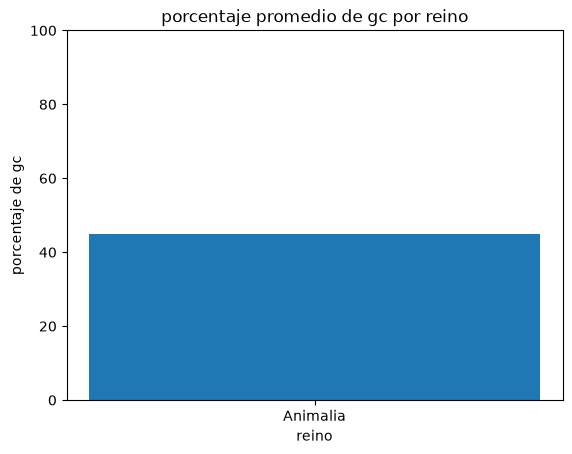

In [12]:
import matplotlib.pyplot as plt

resultados=list(db.secuencias.aggregate([
    {"$lookup":{"from":"especies","localField":"especie","foreignField":"especie","as":"sp"}},
    {"$unwind":"$sp"},
    {"$group":{"_id":"$sp.reino","gc":{"$avg":"$porcentaje_gc"}}},
    {"$sort":{"_id":1}}
]))

print(resultados)

reinos=[]
promedios=[]

for d in resultados:
    reinos.append(d["_id"])
    promedios.append(d["gc"])

plt.bar(reinos,promedios)
plt.title("porcentaje promedio de gc por reino")
plt.xlabel("reino")
plt.ylabel("porcentaje de gc")
plt.ylim(0,100)
plt.show()

In [16]:
print(list(db.secuencias.aggregate([
    {"$lookup":{"from":"especies","localField":"especie","foreignField":"especie","as":"sp"}},
    {"$unwind":"$sp"},
    {"$group":{"_id":"$sp.reino","cantidad":{"$sum":1}}}
])))

[{'_id': 'Animalia', 'cantidad': 2000}]
